# Estimate a $2\theta$ interval from a PDF feature at $r$

A periodic error in the diffraction signal with period $\Delta Q$ can produce a feature near $r$ in the pair distribution function:

$$G(r)=\frac{2}{\pi}\int F(Q)\sin(Qr)\,dQ,\qquad \Delta Q\approx\frac{2\pi}{r}.$$

Using the same convention as the fast extraction notebook,

$$Q=\frac{4\pi}{\lambda}\sin\left(\frac{2\theta}{2}\right),$$

the **local angular period**, in radians, is

$$\Delta(2\theta)\approx\frac{\lambda}{r\cos((2\theta)/2)}.$$

Enter the feature position and wavelength in ångströms below. The plot estimates the **repeat interval in the diffraction background** across the scattering-angle range, not a Bragg angle or a unique cause of the anomaly.

In [13]:
# Edit these inputs, then run this cell and the calculations below.
r_angstrom = 3.0
wavelength_angstrom = 0.1616693159906119

# Default wavelength: the 100579 goniometer calibration in data/ (metres × 1e10).
# Replace it with the wavelength used for your diffraction pattern.

In [14]:
import math


def estimate_tth_steps(r_angstrom, wavelength_angstrom, tth_deg):
    """Return a Fourier period and its angular equivalents at a scattering angle."""
    if not math.isfinite(r_angstrom) or r_angstrom <= 0:
        raise ValueError('r_angstrom must be finite and positive.')
    if not math.isfinite(wavelength_angstrom) or wavelength_angstrom <= 0:
        raise ValueError('wavelength_angstrom must be finite and positive.')
    if not math.isfinite(tth_deg) or not 0 <= tth_deg < 180:
        raise ValueError('tth_deg must be finite and in [0, 180).')

    theta_rad = math.radians(tth_deg / 2)
    delta_q = 2 * math.pi / r_angstrom
    local_period_deg = math.degrees(
        wavelength_angstrom / (r_angstrom * math.cos(theta_rad))
    )

    # Exact forward interval: Q(2θ + Δ) - Q(2θ) = 2*pi/r.
    # Do not clip an unreachable endpoint to 180 degrees.
    endpoint_sine = math.sin(theta_rad) + wavelength_angstrom / (2 * r_angstrom)
    exact_period_deg = (
        2 * math.degrees(math.asin(endpoint_sine)) - tth_deg
        if endpoint_sine <= 1 else None
    )
    return {
        'delta_q_inv_angstrom': delta_q,
        'local_period_deg': local_period_deg,
        'exact_forward_period_deg': exact_period_deg,
        'local_nyquist_step_deg': local_period_deg / 2,
    }


# Validate the inputs and report the angle-independent Q interval.
delta_q_inv_angstrom = estimate_tth_steps(
    r_angstrom, wavelength_angstrom, 0.0
)['delta_q_inv_angstrom']
print(f'PDF feature: r = {r_angstrom:g} Å')
print(f'Wavelength: {wavelength_angstrom:.9g} Å')
print(f'Q repeat interval (2π/r): {delta_q_inv_angstrom:.6g} Å⁻¹')

PDF feature: r = 3 Å
Wavelength: 0.161669316 Å
Q repeat interval (2π/r): 2.0944 Å⁻¹


## Repeat interval versus scattering angle

For the chosen $r$ and wavelength, the local interval increases as $1/\cos((2\theta)/2)$. Compare it with the exact forward interval below. Change the plot limits to match your diffraction range; the default is $0$–$70^\circ$. Exact intervals that would extend past $180^\circ$ are omitted.

These curves describe the angular interval associated with a **fixed $Q$ period**; they do not imply that an artefact with a fixed angular spacing has a unique $r$.

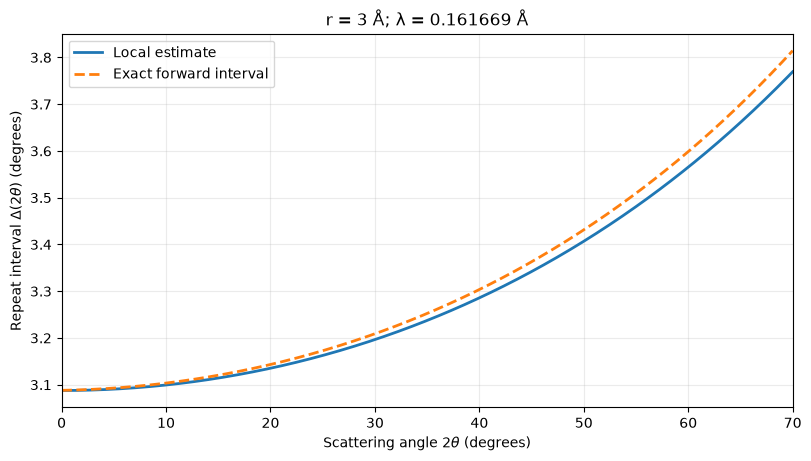

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Match these limits to your diffraction pattern.
plot_tth_min_deg = 0.0
plot_tth_max_deg = 70.0

if not (math.isfinite(plot_tth_min_deg) and math.isfinite(plot_tth_max_deg)
        and 0 <= plot_tth_min_deg < plot_tth_max_deg < 180):
    raise ValueError('Plot limits must satisfy 0 <= min < max < 180 degrees.')

tth_grid_deg = np.linspace(plot_tth_min_deg, plot_tth_max_deg, 500)
step_estimates = [
    estimate_tth_steps(r_angstrom, wavelength_angstrom, float(tth))
    for tth in tth_grid_deg
]
local_intervals_deg = np.array([s['local_period_deg'] for s in step_estimates])
exact_intervals_deg = np.array([
    np.nan if s['exact_forward_period_deg'] is None else s['exact_forward_period_deg']
    for s in step_estimates
])

fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
ax.plot(tth_grid_deg, local_intervals_deg, label='Local estimate', linewidth=2)
ax.plot(tth_grid_deg, exact_intervals_deg, '--', label='Exact forward interval', linewidth=2)
ax.set(
    xlabel=r'Scattering angle $2\theta$ (degrees)',
    ylabel=r'Repeat interval $\Delta(2\theta)$ (degrees)',
    title=f'r = {r_angstrom:g} Å; λ = {wavelength_angstrom:.6g} Å',
    xlim=(plot_tth_min_deg, plot_tth_max_deg),
)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Interpreting the result

- **Repeat interval:** use $\Delta Q=2\pi/r$ to look for a repeating background error. The local angular estimate applies near the chosen $2\theta$; the exact forward interval solves $Q(2\theta+\Delta)-Q(2\theta)=2\pi/r$ without the small-step approximation.
- **Sampling/bin width is different:** if you mean the largest sampling step that can represent correlations up to $r$, the Nyquist boundary is $\delta Q=\pi/r$, or half the local angular period. Use appreciably finer sampling in practice. For uniform $2\theta$ bins, check where the $Q$ spacing per angular step is greatest: at the **lowest** $2\theta$ in your range.
- A repeating error with an approximately fixed angular interval is **not** exactly periodic in $Q$, so it can produce a broadened feature in $r$ rather than a single sharp peak. Finite $Q$ range, windowing and nonperiodic background errors can also generate PDF artefacts; this calculation alone cannot identify their origin.
- If instead you measured the **spacing between ripples in the PDF**, rather than their position at $r$, that is a different interpretation: a localized feature or cutoff in $Q$ produces oscillations with an $r$ period related to its $Q$ position. Do not treat that ripple spacing automatically as the feature position used here.